In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## learning-curve

**Figure 1: Validation accuracy on CIFAR-100 over training for our augmentation, Mixup and the baseline.** Lines show the mean and shaded bands ±1 std over 5 seeds; dashed lines mark the final mean accuracy of ours and Mixup. Ours converges to 0.912 after 50 epochs, above Mixup (0.895) and the baseline (0.878), with bands that do not overlap.

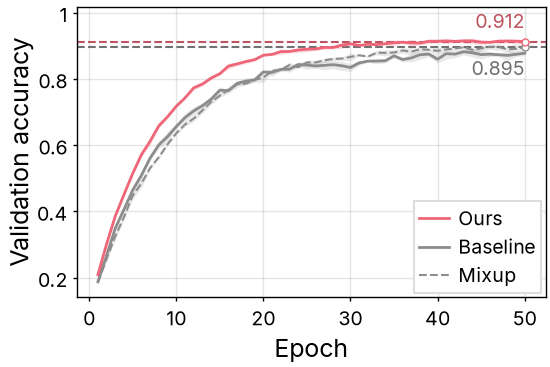

In [2]:
with open("../data/learning-curve.json") as f:
    data = json.load(f)
epochs = np.array(data["epochs"])

fig, ax = plt.subplots(figsize=(2.75, 2))
series = [
    ("Baseline", colors["neutral"], "-", 1.0),
    ("Mixup", colors["neutral"], "--", paper.dashed_width),
    ("Ours", colors["ours"], "-", 1.0),
]
handles = {}
for name, color, linestyle, linewidth in series:
    runs = np.array(data["accuracy"][name])
    mean, std = runs.mean(axis=0), runs.std(axis=0)
    ax.fill_between(epochs, mean - std, mean + std, color=color, alpha=0.2, linewidth=0)
    (handles[name],) = ax.plot(epochs, mean, linestyle=linestyle, linewidth=linewidth, color=color)
    if name != "Baseline":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:#.3g}", color, below=name == "Mixup")

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}".replace("-", "−"))
ax.legend([handles["Ours"], handles["Baseline"], handles["Mixup"]], ["Ours", "Baseline", "Mixup"], loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/learning-curve.pdf")
fig.savefig("../outputs/learning-curve.png")
plt.show()